# WTI Oil: 95% Value at Risk

Training: 2010–2012. Validation: 2013–2017. Test: 2018–2025. The April 2020 arithmetic-return outlier is winsorised at the lower 0.1% quantile before modelling in order to handle an extreme outlier duting covid. 

## 0. Setup

In [ ]:
import time, requests, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats
from statsmodels.graphics.gofplots import qqplot
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from var_utils import *

ALPHA=0.05
WINDOW=504 
WINSOR_LOWER_QUANTILE=0.001

TRAIN_START, TRAIN_END='2010-01-01','2012-12-31'
VALIDATION_START, VALIDATION_END='2013-01-01','2017-12-31'
TEST_START, TEST_END='2018-01-01','2025-12-31'
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})

/Users/andreikh./Repositories/var-estimation/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Download and parse WTI prices

In [ ]:
started=time.perf_counter()
response=requests.get('https://tankermap.com/api/market-data/wti',params={'period':'MAX'},timeout=90)
response.raise_for_status()

bars=pd.DataFrame(response.json()['bars'])
dates=pd.to_datetime(bars['time'],errors='coerce')
close=pd.to_numeric(bars['close'],errors='coerce')
invalid=int(dates.isna().sum()); missing=int(close.isna().sum())
parsed=pd.DataFrame({'date':dates,'close':close}).dropna()

duplicates=int(parsed.duplicated('date').sum())
prices=parsed.drop_duplicates('date',keep='last').set_index('date')['close'].sort_index().loc['2010-01-01':'2025-12-31']

elapsed=time.perf_counter()-started
expected=16*252
print_download_summary({'Requested symbol':'WTI',
                        'Successful downloads':'1 / 1',
                        'Total observations':f'{len(bars):,}',
                        'Duplicate observations':f'{duplicates:,}',
                        'Missing close values':f'{missing:,}',
                        'Invalid timestamps':f'{invalid:,}',
                        'First study observation':f'{prices.index.min():%Y-%m-%d}',
                        'Last study observation':f'{prices.index.max():%Y-%m-%d}',
                        'Expected observations':f'{expected:,} (16 × 252 trading days)',
                        'Actual observations':f'{len(prices):,}',
                        'Coverage ratio':f'{len(prices)/expected:.2%}',
                        'Elapsed time':f'{elapsed:.3f}s',
                        'Download size':f'{len(response.content)/1e6:.3f} MB'
                        })

Download Summary
----------------------------------------------------------------------------
Requested symbol                                   WTI
Successful downloads                             1 / 1
Total observations                               5,142
Duplicate observations                               0
Missing close values                                 0
Invalid timestamps                                   0
First study observation                     2010-01-04
Last study observation                      2025-12-31
Expected observations         4,032 (16 × 252 trading days)
Actual observations                              4,028
Coverage ratio                                  99.90%
Elapsed time                                    1.174s
Download size                                 0.704 MB
----------------------------------------------------------------------------


## 2. Returns, winsorisation, and sample coverage

In [4]:
returns_raw=prices.pct_change().dropna().rename('Raw return')
winsor_floor=returns_raw.quantile(WINSOR_LOWER_QUANTILE)
returns=returns_raw.clip(lower=winsor_floor).rename('Winsorised return')
print(f'Lower winsorisation floor: {winsor_floor:.3%}; observations capped: {(returns_raw<winsor_floor).sum()}')
train=returns.loc[TRAIN_START:TRAIN_END]; validation=returns.loc[VALIDATION_START:VALIDATION_END]
development=returns.loc[TRAIN_START:VALIDATION_END]; test=returns.loc[TEST_START:TEST_END]
splits={'Training':train,'Validation':validation,'Test':test}; print_split_summary(splits)

Lower winsorisation floor: -22.458%; observations capped: 5
Sample Coverage
Sample          First return    Last return       Observations
----------------------------------------------------------------------------
Training        2010-01-05      2012-12-31           755
Validation      2013-01-02      2017-12-29         1,259
Test            2018-01-02      2025-12-31         2,013


## 3. Initial data exploration

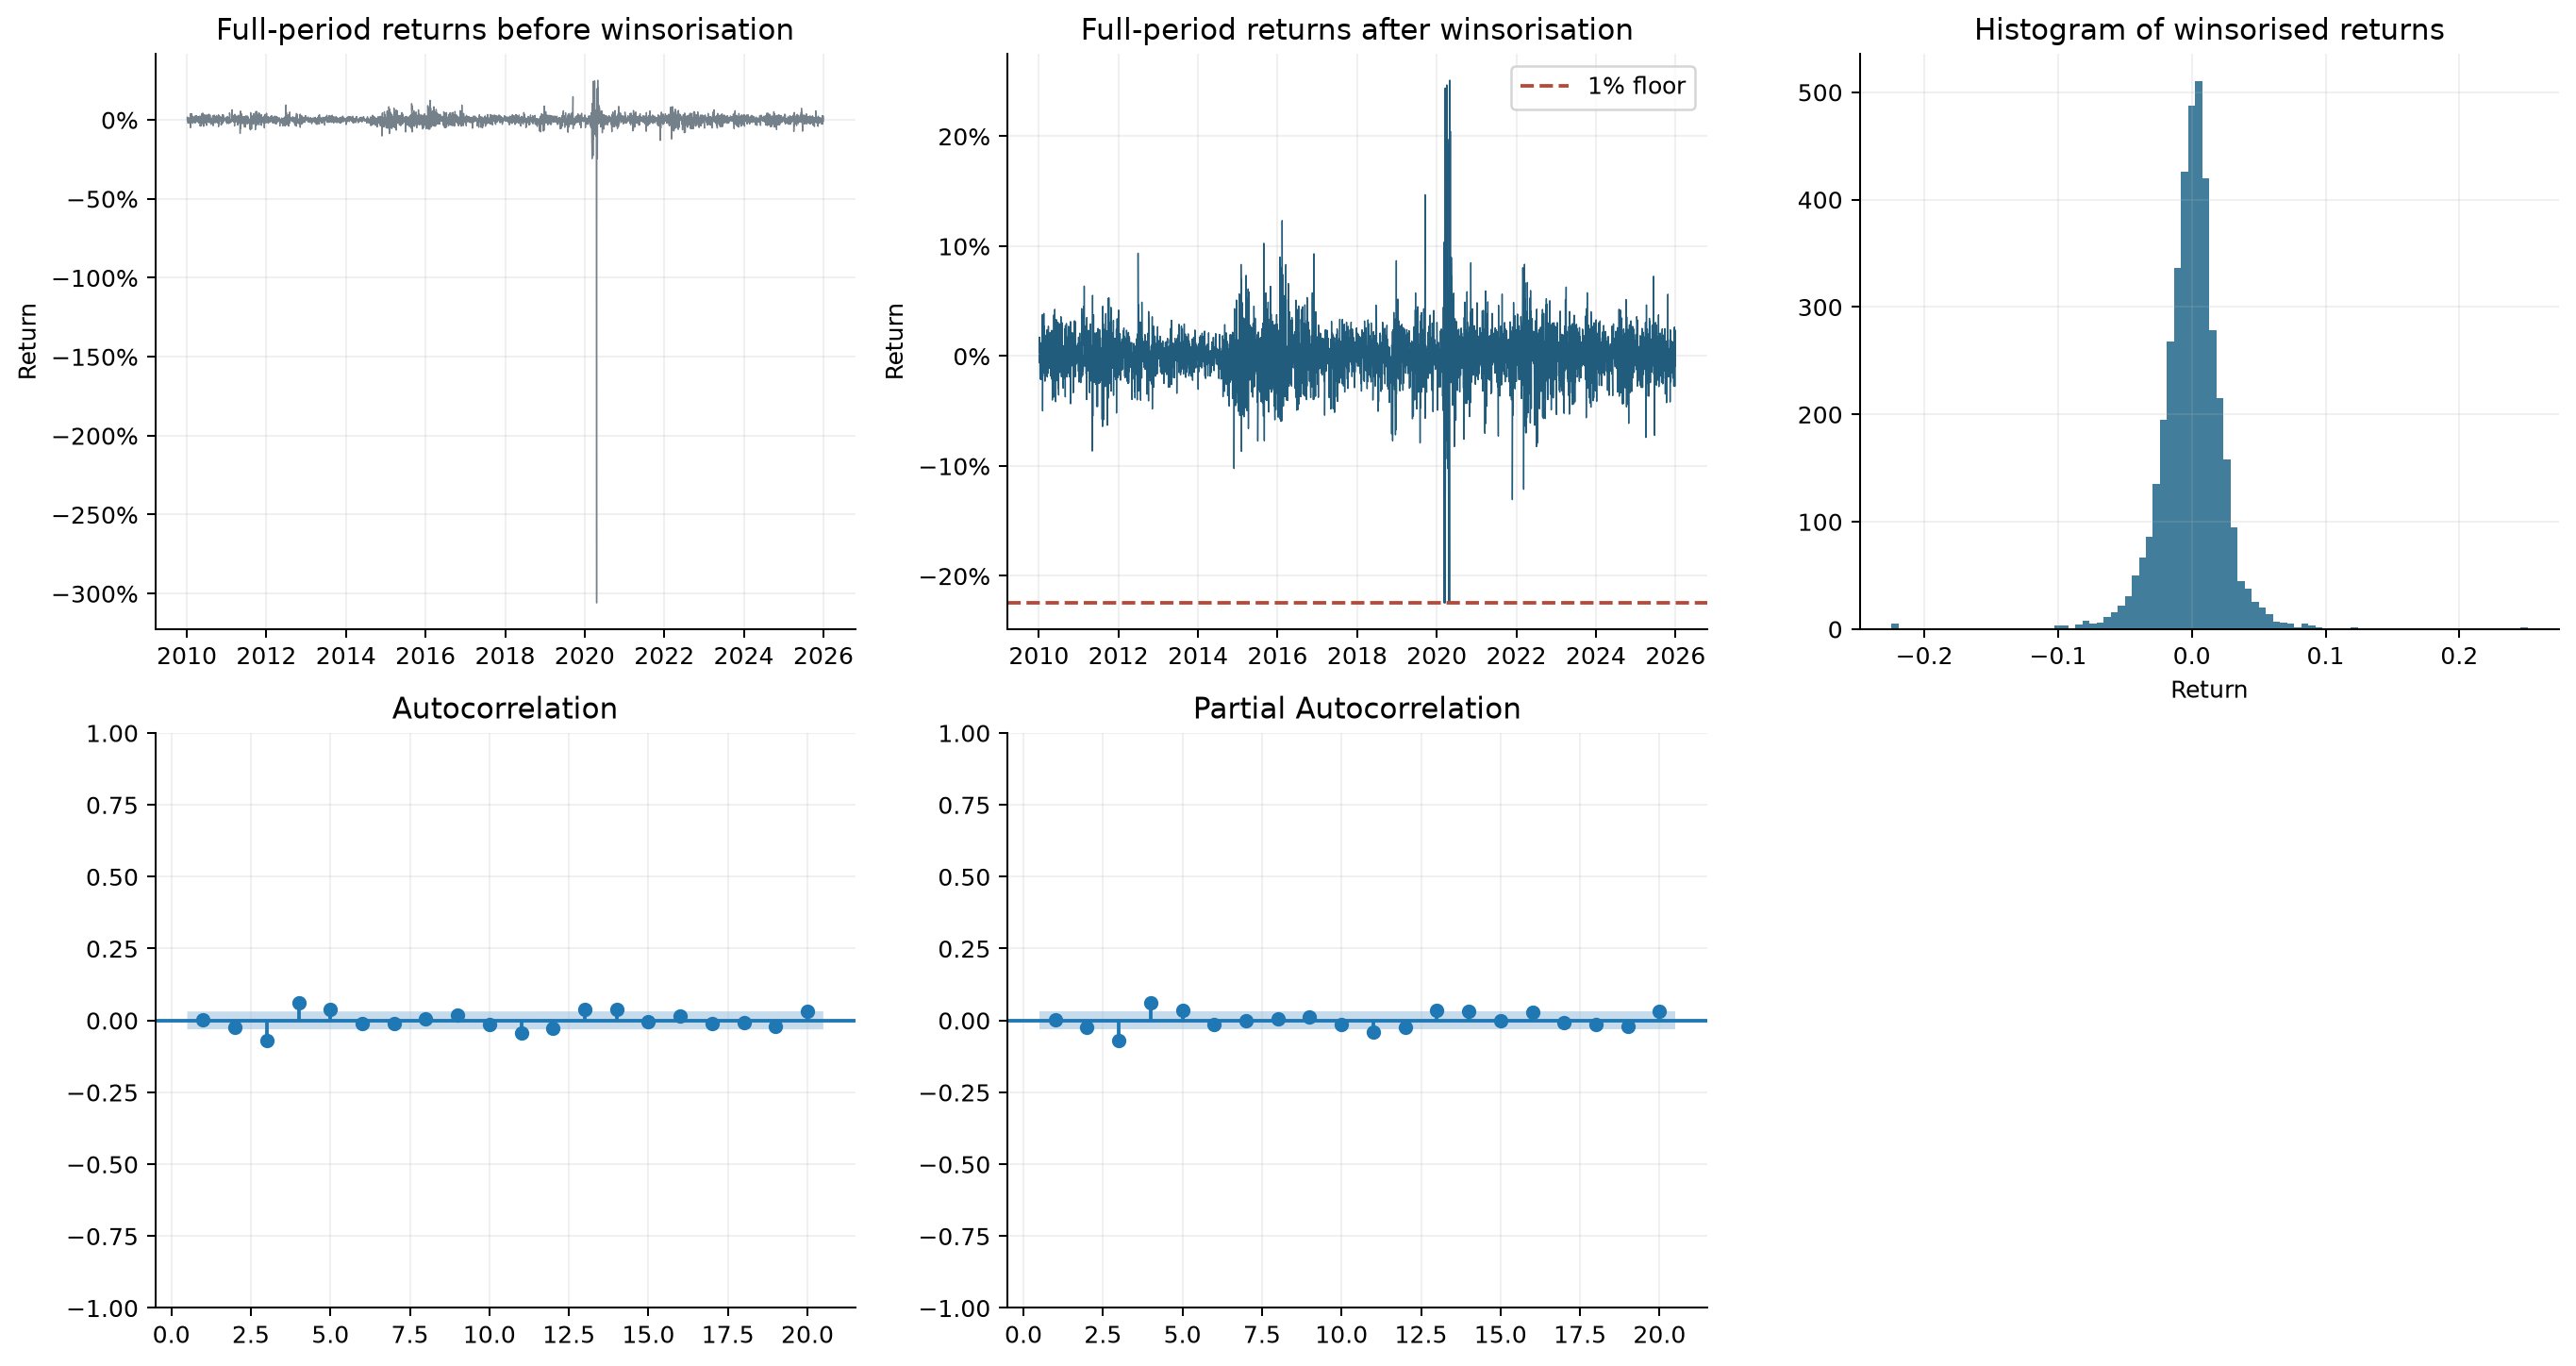

In [6]:
fig,axes=plt.subplots(2,3,figsize=(15,8))
axes[0,0].plot(returns_raw.index,returns_raw,lw=.55,color='#75818a'); axes[0,0].set(title='Full-period returns before winsorisation',ylabel='Return')
axes[0,1].plot(returns.index,returns,lw=.55,color='#225c7c'); axes[0,1].axhline(winsor_floor,color='#b64a3a',ls='--',label='1% floor'); axes[0,1].set(title='Full-period returns after winsorisation',ylabel='Return'); axes[0,1].legend()
axes[0,2].hist(returns,bins=90,color='#427e9b'); axes[0,2].set(title='Histogram of winsorised returns',xlabel='Return')

plot_acf(returns,lags=20,zero=False,ax=axes[1,0]); 
plot_pacf(returns,lags=20,zero=False,method='ywm',ax=axes[1,1]); axes[1,2].axis('off')

for ax in axes.flat[:2]: ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout(); plt.show()

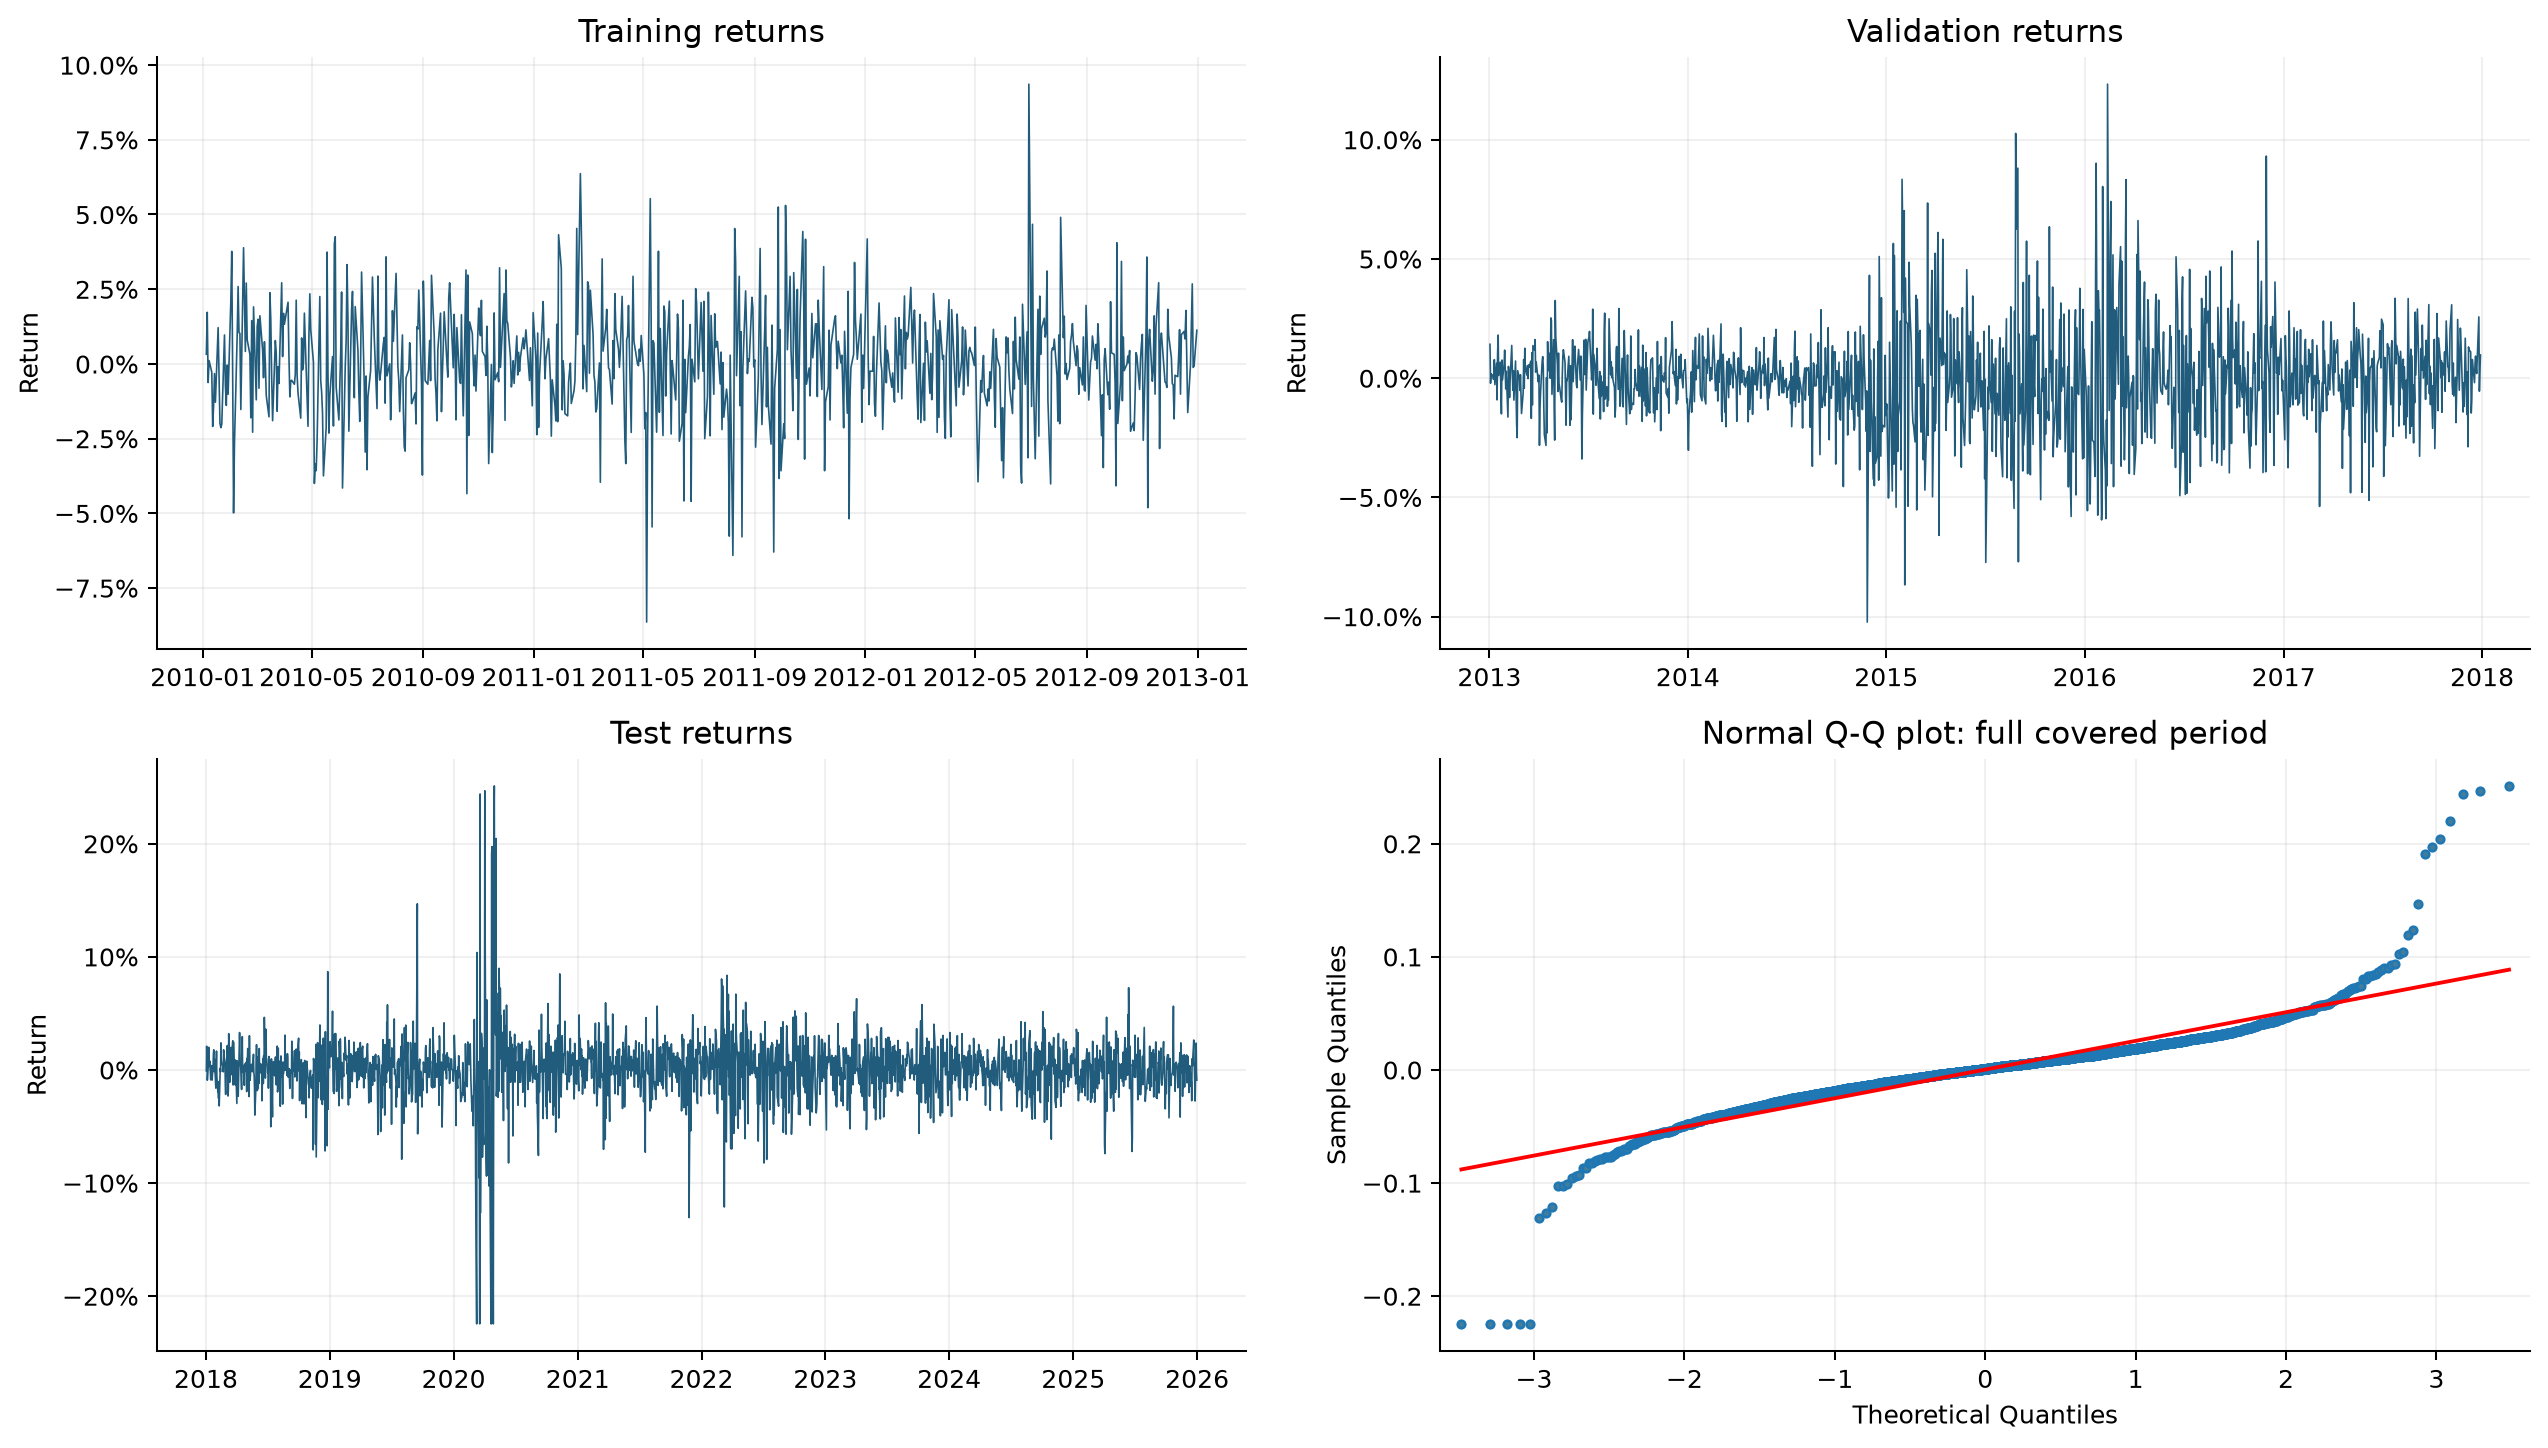

In [7]:
fig,axes=plt.subplots(2,2,figsize=(14,8))
for ax,(name,sample) in zip(axes.flat[:3],splits.items()):
 ax.plot(sample.index,sample,lw=.65,color='#225c7c'); ax.set(title=f'{name} returns',ylabel='Return'); ax.yaxis.set_major_formatter(PercentFormatter(1))
qqplot(returns,line='s',ax=axes[1,1],markerfacecolor='#427e9b',markersize=3); axes[1,1].set_title('Normal Q-Q plot: full covered period')
fig.tight_layout(); plt.show()

## 4. Descriptive statistics, normality, and Ljung–Box tests

In [8]:
print_return_summary(returns, asset='WTI', alpha=ALPHA)

Return Distribution Summary
Asset:          WTI
Variable:       Winsorised arithmetic returns
Frequency:      Daily
Sample:         2010-01-05 to 2025-12-31
Observations:   4,027
Missing:        0

Descriptive Statistics
----------------------------------------------------------------------------
Statistic                          Value
----------------------------------------------------------------------------
Mean                            2.37e-04
Std. deviation                     0.025
Variance                           0.001
Minimum                           -0.225
1st Quartile                      -0.011
Median                             0.001
3rd Quartile                       0.012
Maximum                            0.251
Skewness                           0.245
Excess kurtosis                   19.394

Normality Tests
Test                       Statistic     p-value    Decision
----------------------------------------------------------------------------
Shapiro-Wilk       

## 5–6. Distribution fitting and GH Monte Carlo VaR

Distribution Fit Comparison
Distribution            Observations    Log-likelihood         AIC         BIC
----------------------------------------------------------------------------
Normal                         2,014          4955.847   -9907.694   -9896.478
Student-t                      2,014          5059.967  -10113.934  -10097.111
Hansen skew-t                  2,014          5060.589  -10113.178  -10090.747
GH                             2,014          5063.621  -10117.242  -10089.202
Lower AIC and BIC indicate preferred in-sample fit.
GH 5% return quantile: -3.326%
Monte Carlo 5% return quantile: -3.291%


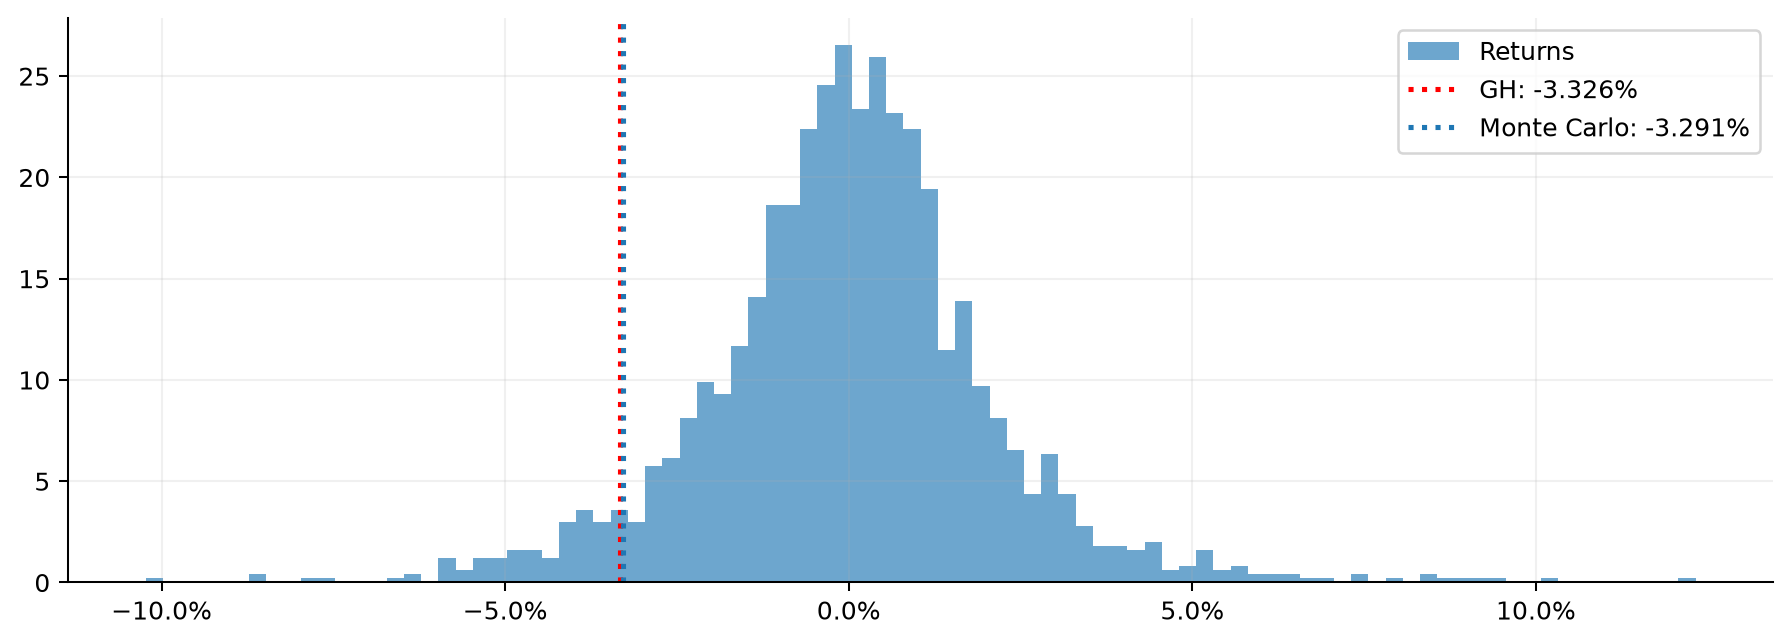

In [11]:
distribution_fits,_=fit_distributions(development); 
print_distribution_summary(distribution_fits)

gh_params=distribution_fits['GH']['params']; simulation=stats.genhyperbolic.rvs(*gh_params,size=10_000,random_state=np.random.default_rng(SEED))
gh_q=stats.genhyperbolic.ppf(ALPHA,*gh_params); mc_q=np.quantile(simulation,ALPHA)
print(f'GH 5% return quantile: {gh_q:.3%}'); print(f'Monte Carlo 5% return quantile: {mc_q:.3%}')

fig,ax=plt.subplots(figsize=(12,4))
ax.hist(development,bins=90,density=True,alpha=.65,label='Returns')
ax.axvline(gh_q,ls=':',lw=2,label=f'GH: {gh_q:.3%}',color='r')
ax.axvline(mc_q,ls=':',lw=2,label=f'Monte Carlo: {mc_q:.3%}') 
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
plt.show()

## 7–8. Rolling GH VaR and backtesting

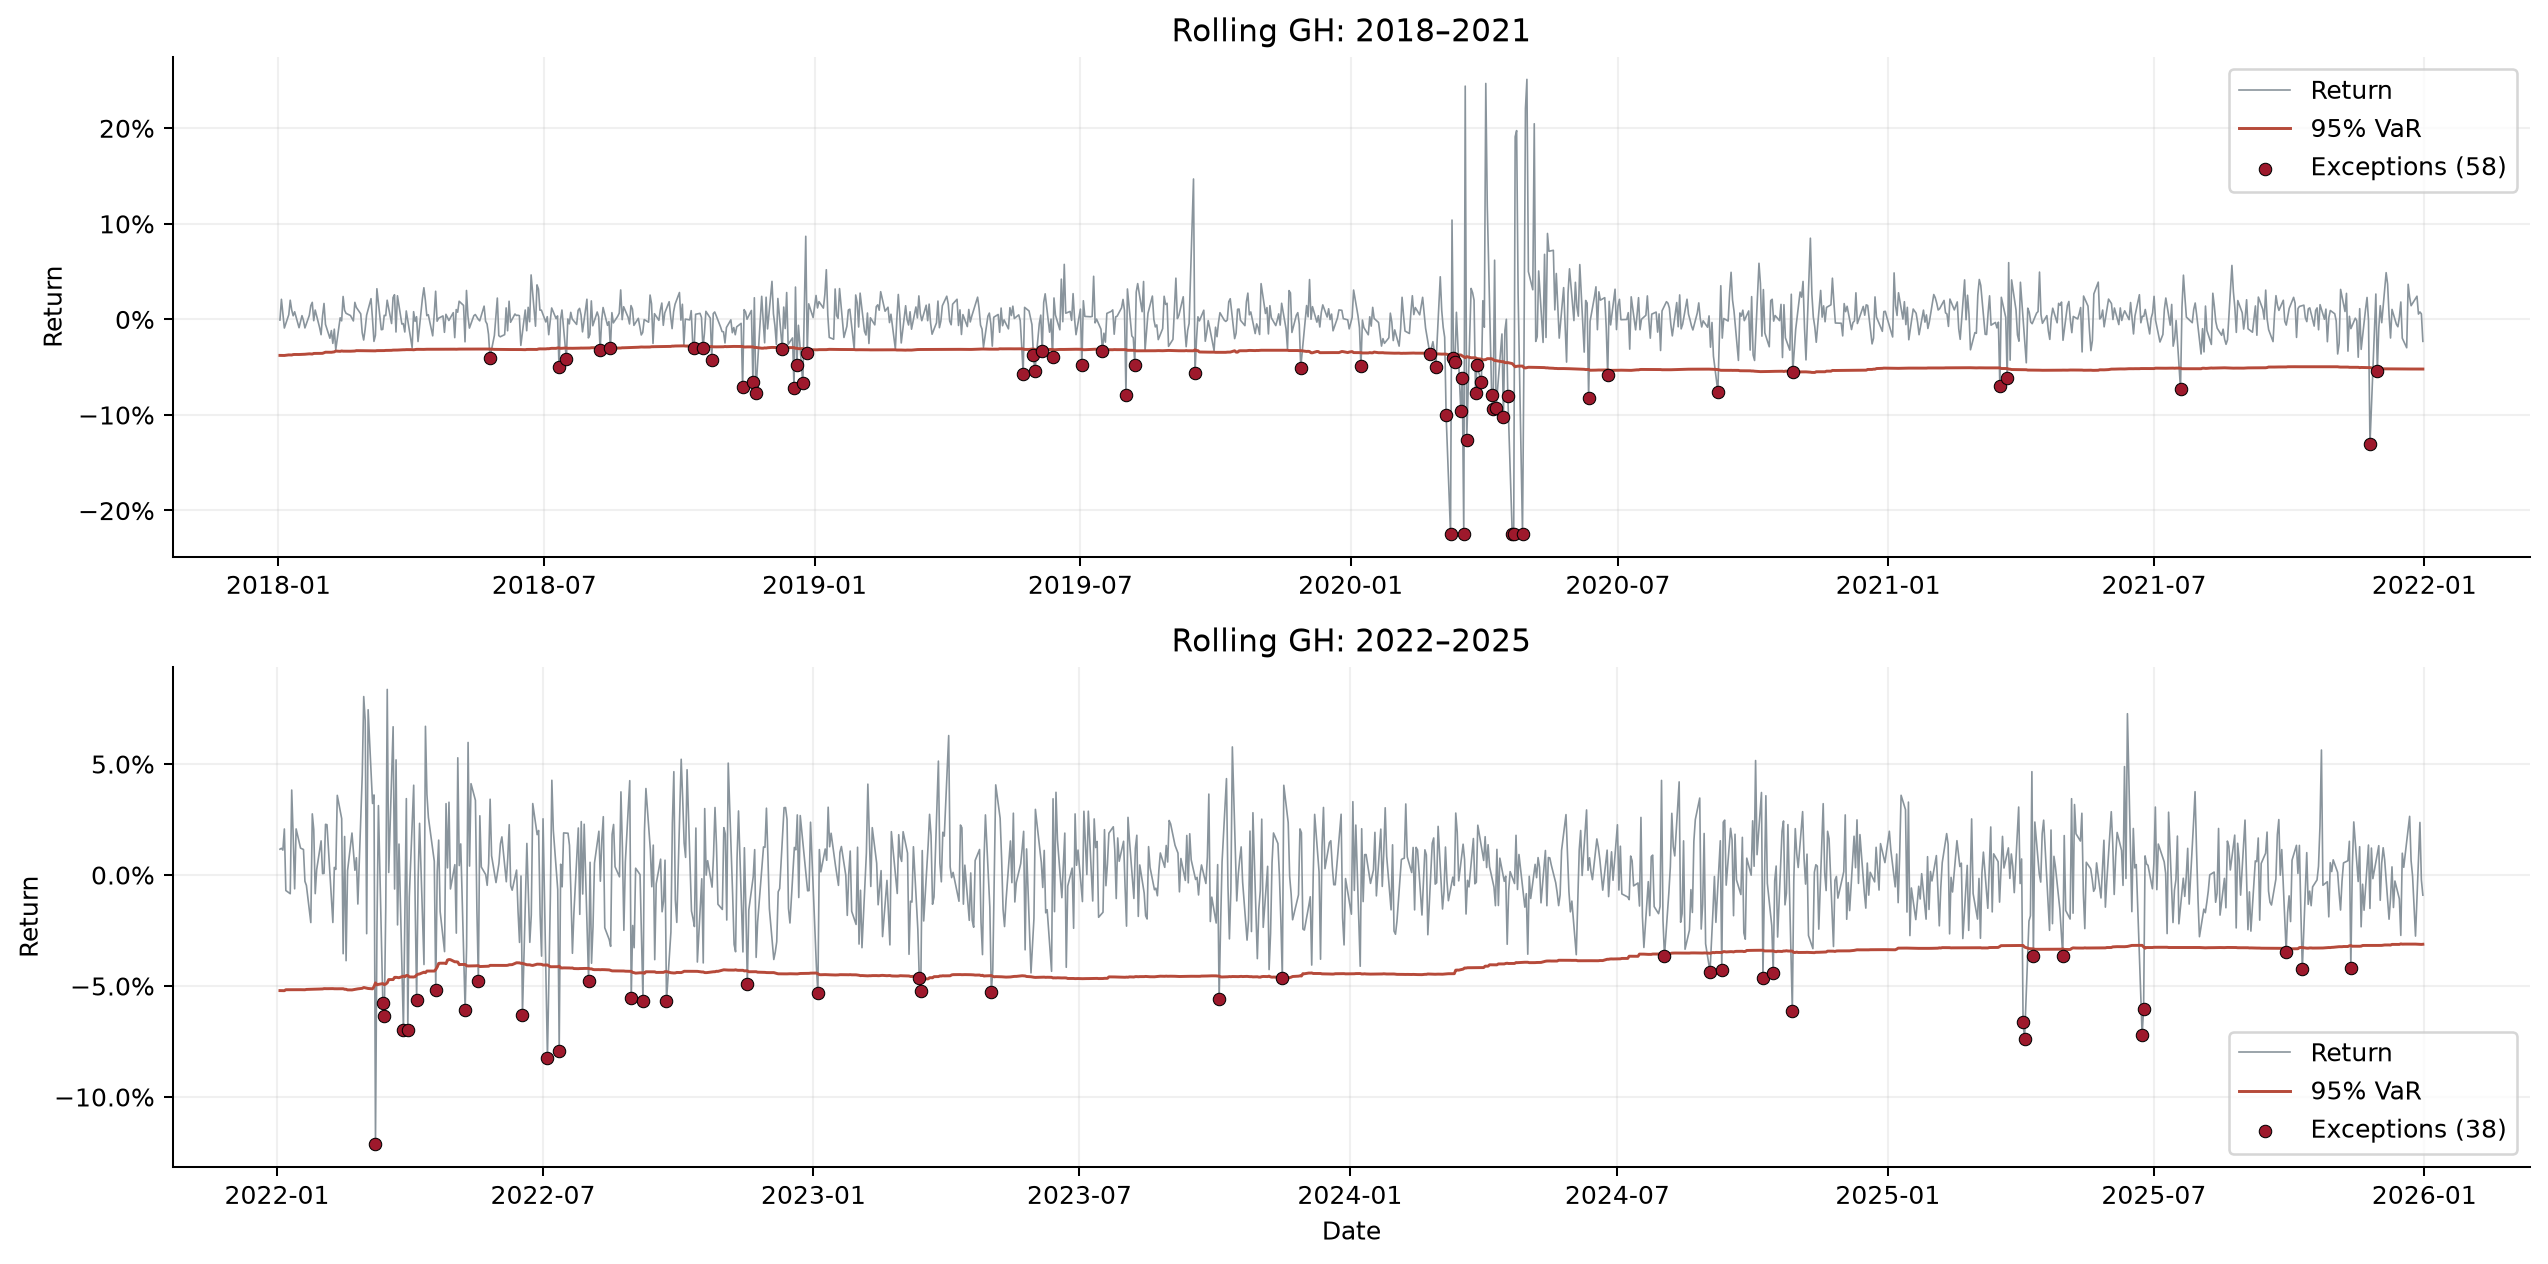

In [16]:
gh_var=rolling_forecasts(returns,'GH',TEST_START,TEST_END,window=WINDOW,alpha=ALPHA,gh_workers=4).rename('Rolling GH')
plot_var_periods(test,gh_var,'Rolling GH')
plt.show()

In [20]:
gh_backtest=backtest(test,gh_var,ALPHA)
print_backtest_summary('Rolling GH',gh_backtest,ALPHA)

VaR Backtesting Results
Model:          Rolling GH
VaR level:      5.0%
Observations:   2,013

Coverage
----------------------------------------------------------------------------
Exceptions:          96 / 2013
Expected rate:       5.000%
Observed rate:       4.769%
Expected exceptions: 100.650

Transition Matrix
----------------------------------------------------------------------------
                          I(t) = 0      I(t) = 1         Total
I(t-1) = 0                    1834            82          1916
I(t-1) = 1                      82            14            96
Total                         1916            96          2012
P(0 -> 1) = 0.043    P(1 -> 1) = 0.146

Statistical Tests
Test                         Statistic     p-value    Decision
----------------------------------------------------------------------------
Kupiec uncond. coverage          0.230       0.632        PASS
Christoffersen independence      14.504      <0.001        FAIL
Christoffersen cond. cov.     

## 9. GARCH model comparison

In [12]:
garch_fits={name:fit_garch(development,name) for name in ['GARCH(1,1)','GARCH(2,2)','GJR-GARCH(1,1)']}
print_garch_summary(garch_fits)

GARCH Model Comparison
Parameter                GARCH(1,1)         GARCH(2,2)     GJR-GARCH(1,1)
----------------------------------------------------------------------------
mu                         2.87e-04           3.30e-04           3.60e-05
omega                      2.36e-06           4.55e-06           1.16e-06
alpha[1]                   0.061***            0.047**              0.010
alpha[2]                          —           0.074***                  —
gamma[1]                          —                  —           0.068***
beta[1]                    0.934***              0.000           0.954***
beta[2]                           —           0.871***                  —
nu                         7.715***           7.953***           8.595***
----------------------------------------------------------------------------
Log-likelihood             5227.720           5229.187           5241.533
AIC                          -5.186             -5.186             -5.199
BIC      

## 10–11. Rolling GJR-GARCH VaR and backtesting

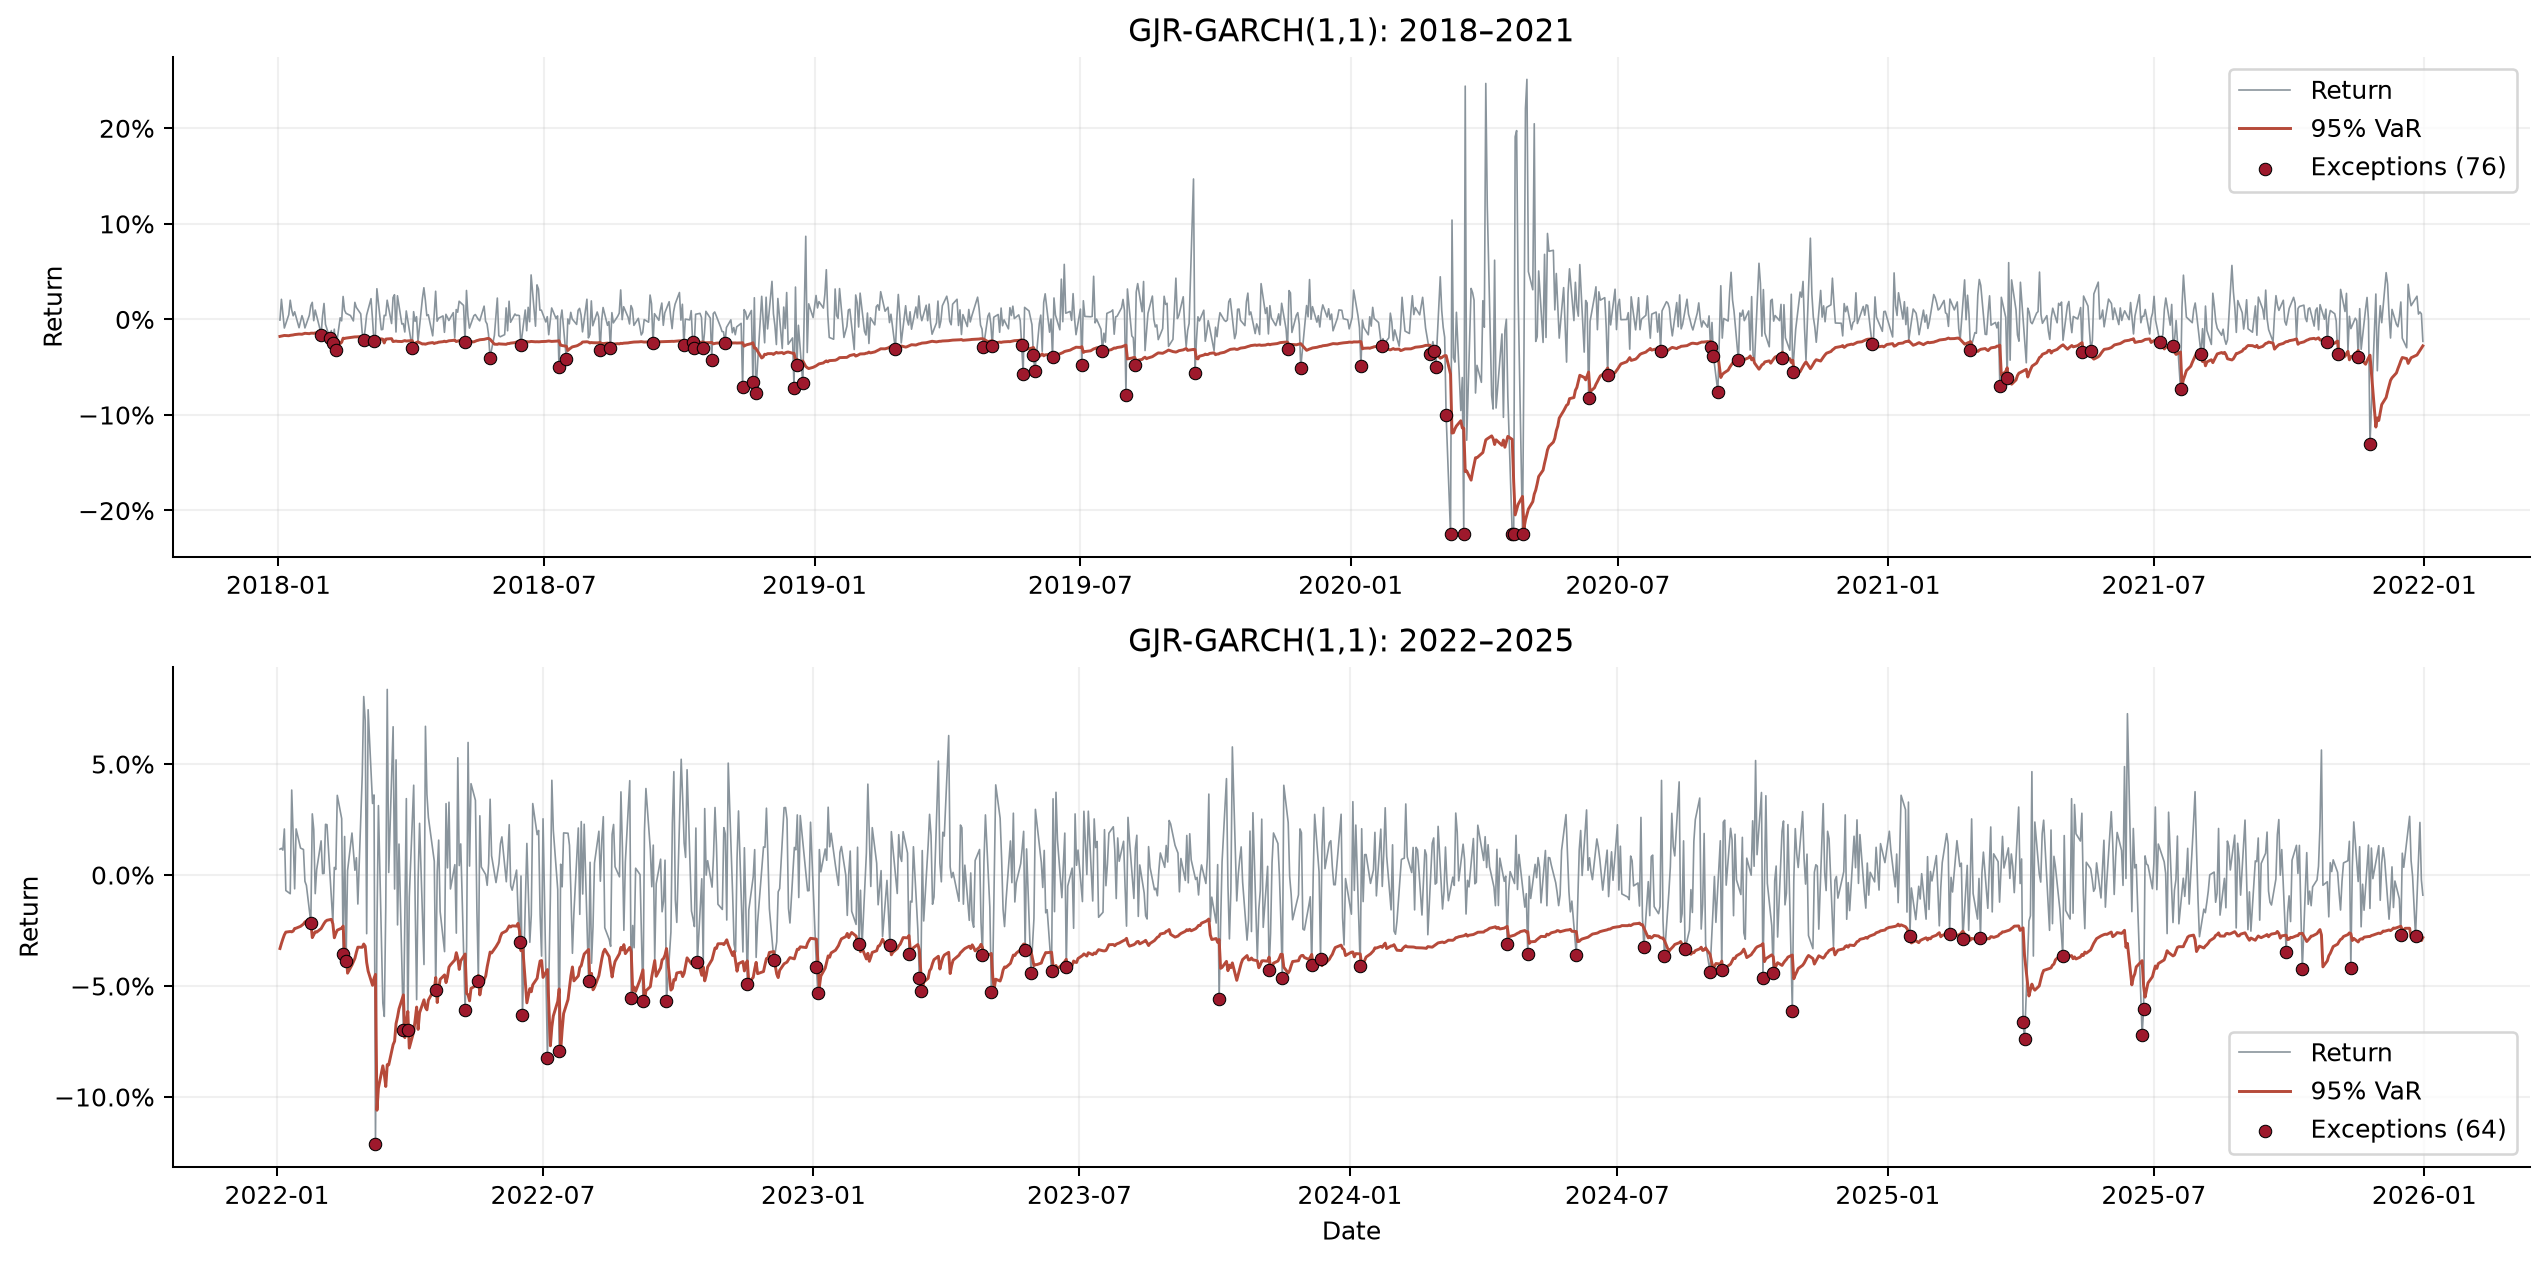

In [15]:
gjr_var=rolling_forecasts(returns,'GJR-GARCH',TEST_START,TEST_END,window=WINDOW,alpha=ALPHA).rename('GJR-GARCH')

plot_var_periods(test,gjr_var,'GJR-GARCH(1,1)')
plt.show(); gjr_backtest=backtest(test,gjr_var,ALPHA)

In [21]:
print_backtest_summary('GJR-GARCH(1,1)',gjr_backtest,ALPHA)

VaR Backtesting Results
Model:          GJR-GARCH(1,1)
VaR level:      5.0%
Observations:   2,013

Coverage
----------------------------------------------------------------------------
Exceptions:          140 / 2013
Expected rate:       5.000%
Observed rate:       6.955%
Expected exceptions: 100.650

Transition Matrix
----------------------------------------------------------------------------
                          I(t) = 0      I(t) = 1         Total
I(t-1) = 0                    1743           129          1872
I(t-1) = 1                     129            11           140
Total                         1872           140          2012
P(0 -> 1) = 0.069    P(1 -> 1) = 0.079

Statistical Tests
Test                         Statistic     p-value    Decision
----------------------------------------------------------------------------
Kupiec uncond. coverage         14.513      <0.001        FAIL
Christoffersen independence       0.181       0.670        PASS
Christoffersen cond. cov.

## 12. CAViaR(1,1) comparison

In [22]:
caviar_fits={name:fit_caviar(development,spec=name,alpha=ALPHA,seed=SEED,starts=12) for name in ['SAV','AS','INDGARCH']}
print_caviar_summary(caviar_fits,development,ALPHA)

CAViaR Model Comparison
Parameter                       SAV                 AS           INDGARCH
----------------------------------------------------------------------------
Beta 0                       -0.117             -0.016             0.444*
Beta 1                     0.892***           0.983***           0.870***
Gamma 1                   -0.156***             0.025*           0.242***
Gamma 2                           —          -0.074***                  —

95% confidence intervals
----------------------------------------------------------------------------
Parameter                       SAV                 AS           INDGARCH
Beta 0              [-0.238, 0.003] [-0.031, 1.60e-04]     [0.043, 0.845]
Beta 1               [0.829, 0.954]     [0.970, 0.996]     [0.807, 0.932]
Gamma 1            [-0.230, -0.082]     [0.001, 0.049]     [0.144, 0.340]
Gamma 2                           —   [-0.102, -0.046]                  —
--------------------------------------------------------

## 13–14. Rolling AS-CAViaR VaR and backtesting

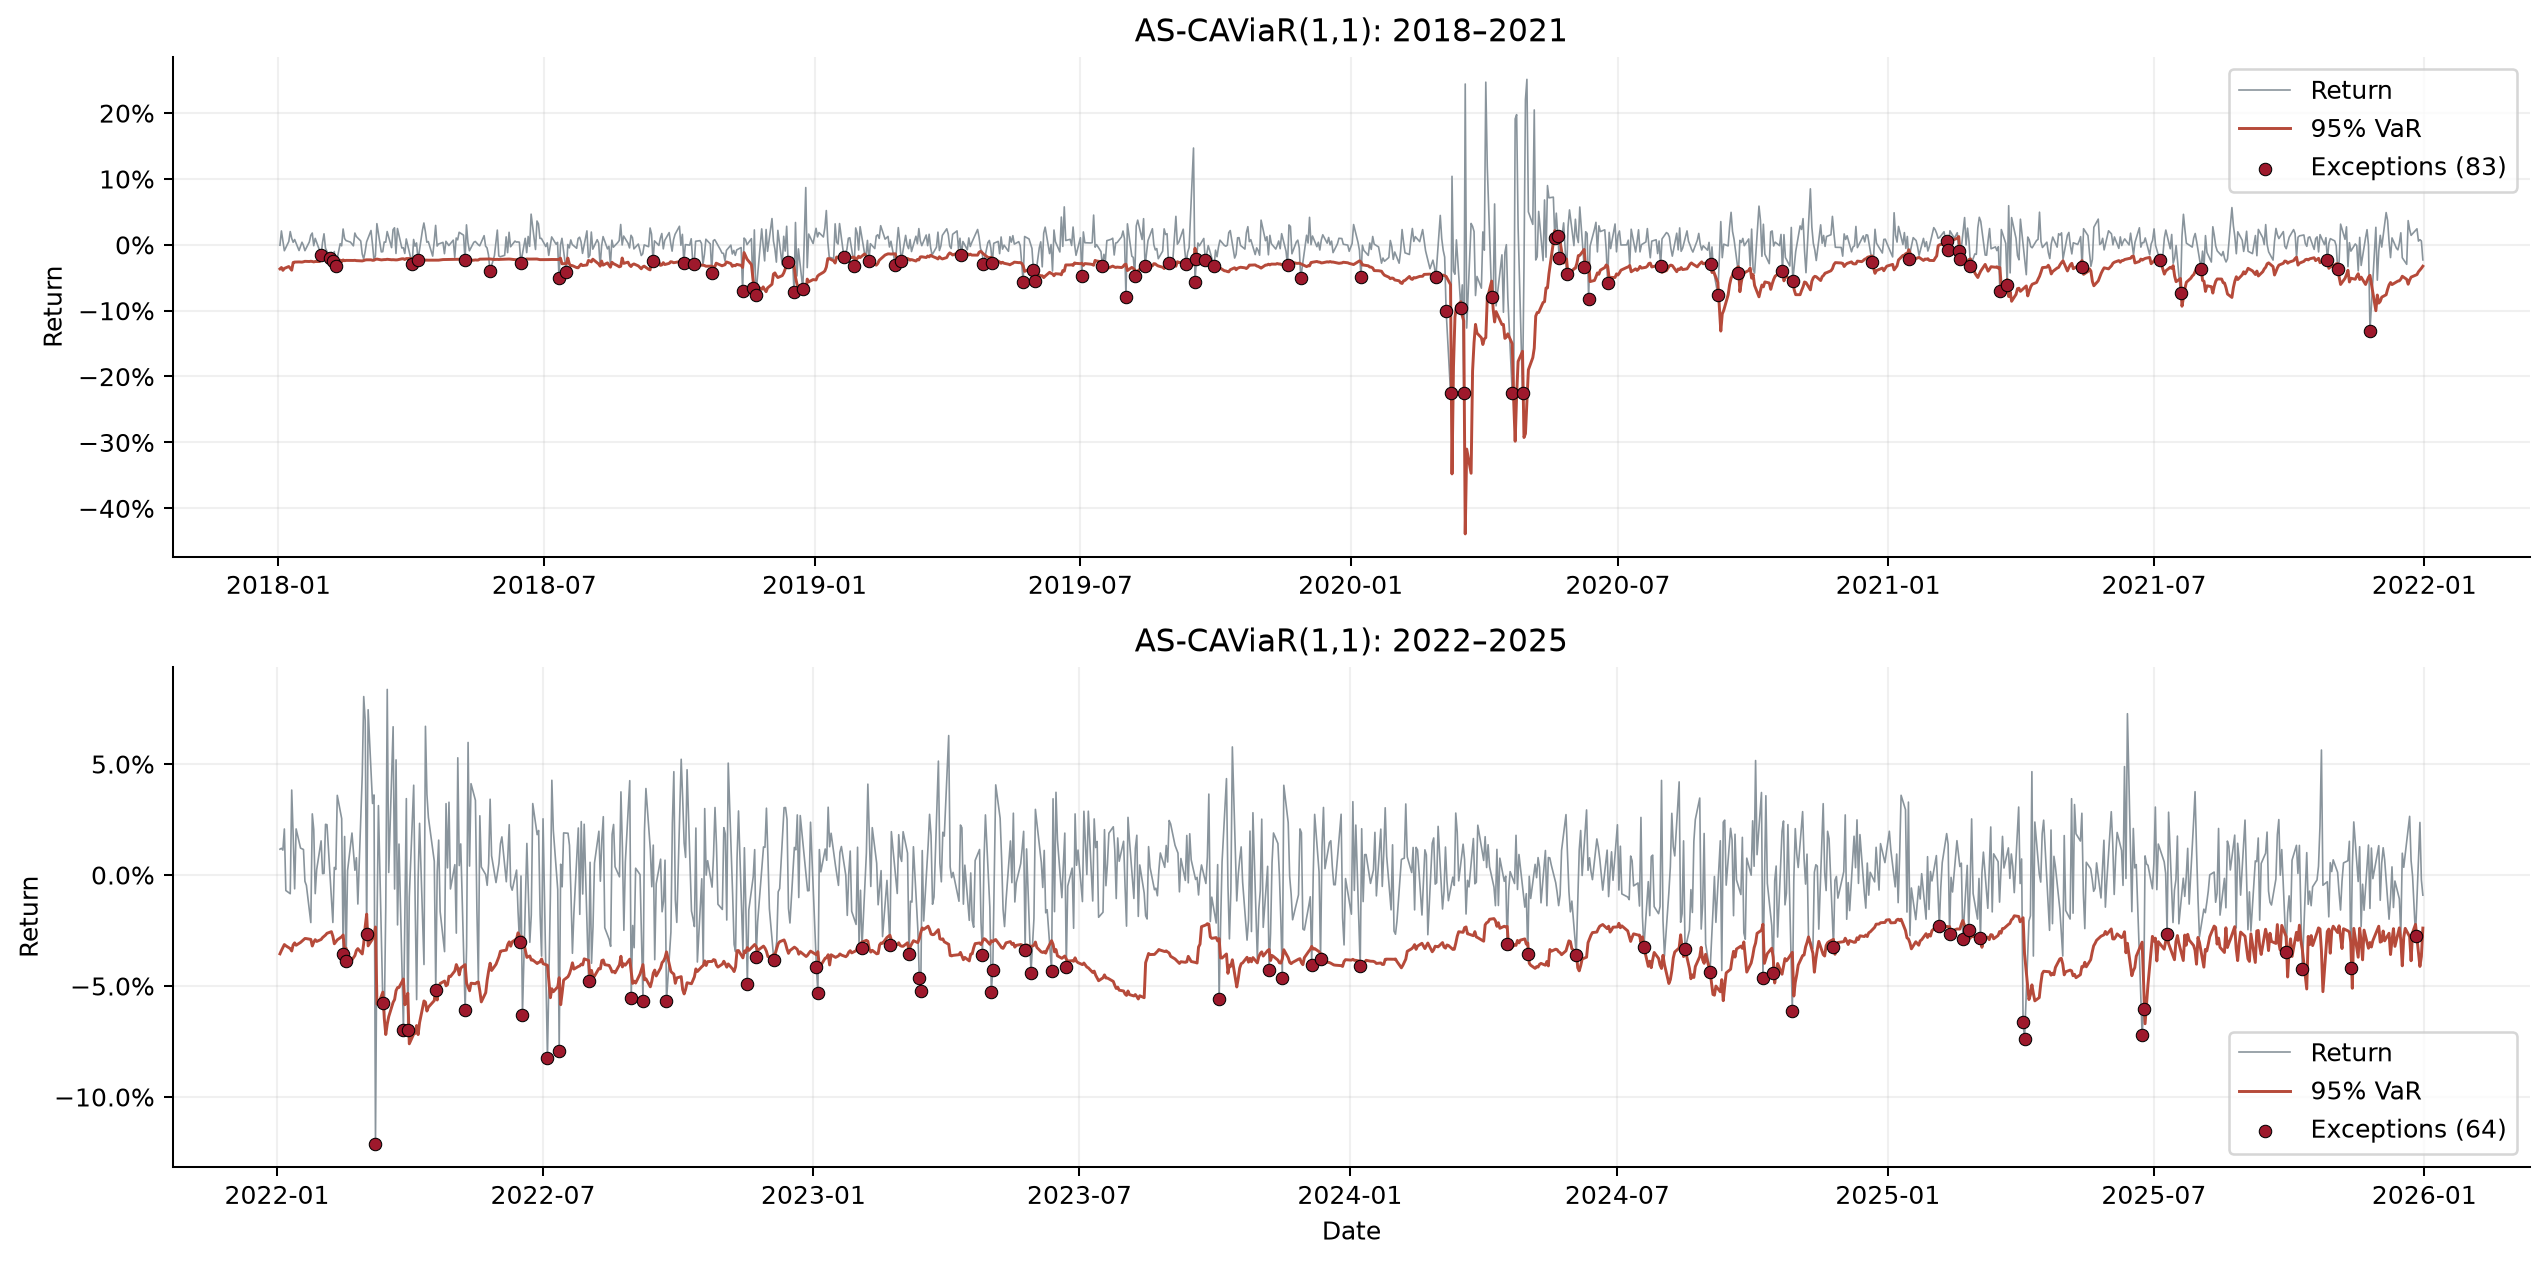

In [23]:
as_var=rolling_forecasts(returns,'AS-CAViaR',TEST_START,TEST_END,window=WINDOW,alpha=ALPHA,caviar_starts=5).rename('AS-CAViaR')
plot_var_periods(test,as_var,'AS-CAViaR(1,1)')
plt.show()
as_backtest=backtest(test,as_var,ALPHA)

In [24]:
print_backtest_summary('AS-CAViaR(1,1)',as_backtest,ALPHA)

VaR Backtesting Results
Model:          AS-CAViaR(1,1)
VaR level:      5.0%
Observations:   2,013

Coverage
----------------------------------------------------------------------------
Exceptions:          147 / 2013
Expected rate:       5.000%
Observed rate:       7.303%
Expected exceptions: 100.650

Transition Matrix
----------------------------------------------------------------------------
                          I(t) = 0      I(t) = 1         Total
I(t-1) = 0                    1729           136          1865
I(t-1) = 1                     136            11           147
Total                         1865           147          2012
P(0 -> 1) = 0.073    P(1 -> 1) = 0.075

Statistical Tests
Test                         Statistic     p-value    Decision
----------------------------------------------------------------------------
Kupiec uncond. coverage         19.795      <0.001        FAIL
Christoffersen independence       0.007       0.932        PASS
Christoffersen cond. cov.

## 15. Final VaR comparison

In [27]:
forecasts=pd.concat([gh_var,gjr_var,as_var],axis=1); backtests={name:backtest(test,forecasts[name],ALPHA) for name in forecasts}
print_final_backtest_summary(backtests)

VaR Model Comparison
Model                   Observations    Exceptions        Rate  Rejected tests
----------------------------------------------------------------------------
Rolling GH                     2,013            96      4.769%               3
GJR-GARCH                      2,013           140      6.955%               4
AS-CAViaR                      2,013           147      7.303%               4
----------------------------------------------------------------------------
Model                       Kupiec p         IND p          CC p            DQ p
Rolling GH                     0.632        <0.001        <0.001          <0.001
GJR-GARCH                     <0.001         0.670        <0.001          <0.001
AS-CAViaR                     <0.001         0.932        <0.001          <0.001
----------------------------------------------------------------------------
Model                          Lopez      Quantile   Blanco-Ihle
Rolling GH                     0.048       

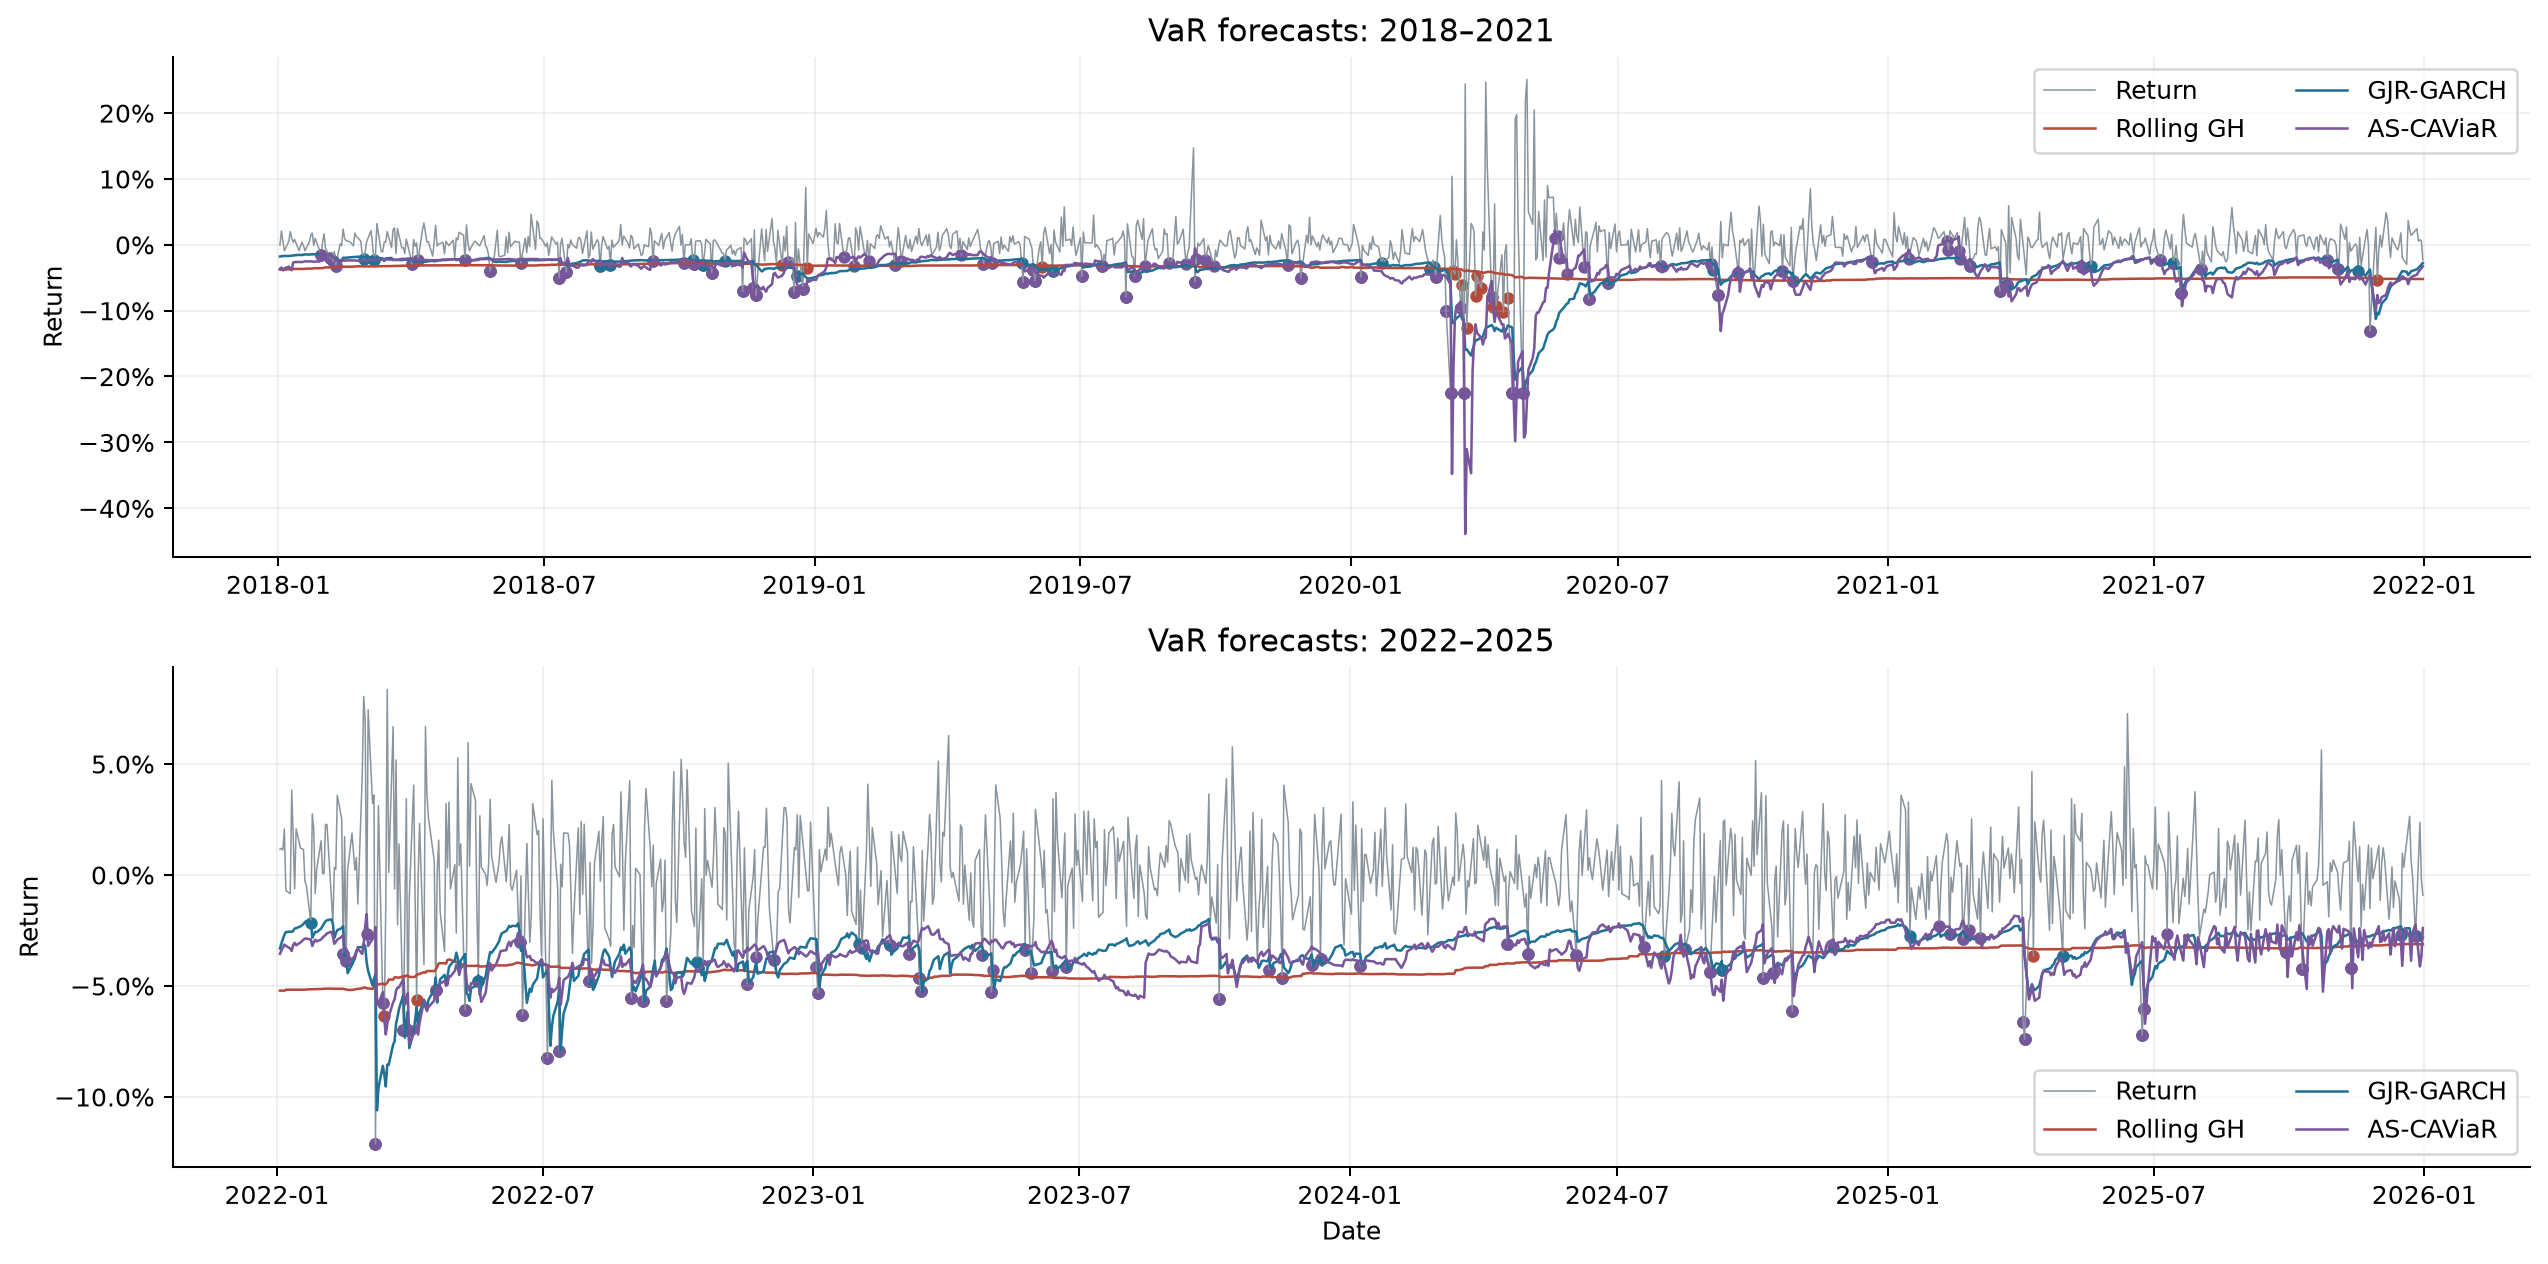

In [28]:
fig,axes=plt.subplots(2,1,figsize=(14,7)); colors={'Rolling GH':'#b64a3a','GJR-GARCH':'#1f7295','AS-CAViaR':'#78569c'}
for ax,(start,end) in zip(axes,[('2018','2021'),('2022','2025')]):
    y=test.loc[start:end]; ax.plot(y.index,y,color='#89949c',lw=.6,label='Return')
    for name in forecasts:
        q=forecasts[name].loc[start:end]
        hit=y<q
        ax.plot(q.index,q,color=colors[name],lw=1,label=name)
        ax.scatter(q.index[hit],y[hit],s=15,color=colors[name])
        ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title=f'VaR forecasts: {start}–{end}',ylabel='Return') 
    ax.legend(ncol=2)
axes[-1].set_xlabel('Date')
fig.tight_layout()
plt.show()

## 16. Pairwise Diebold–Mariano tests

In [29]:
dm_results=pairwise_dm(test,forecasts,ALPHA); print_dm_summary(dm_results)

Diebold-Mariano Test Results
Loss function: Quantile loss     Variance estimator: HAC     Significance: 0.05
----------------------------------------------------------------------------
Model A             Model B                 DM stat.     p-value      Holm p    Mean diff.
----------------------------------------------------------------------------
Rolling GH          GJR-GARCH                  2.239       0.025       0.076      4.31e-04
Rolling GH          AS-CAViaR                  1.610       0.108       0.215      3.31e-04
GJR-GARCH           AS-CAViaR                 -1.498       0.134       0.215     -9.98e-05
A negative statistic favours Model A. Holm p-values adjust for three comparisons.
